---
title: "Figures: The Ramsey/Cass-Koopmans (RCK) Model"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=RamseyCassKoopmans.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/growth/RamseyCassKoopmans/RamseyCassKoopmans.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/growth/RamseyCassKoopmans/RamseyCassKoopmans.ipynb).

In [the RCK model](https://intertemporal-choice.github.io/content/growth/ramseycasskoopmans), capital $k$ and consumption $c$ are measured per efficiency unit of labor, output is $k^{\alpha}$, population grows at the rate $\xi$ and labor productivity at the rate $\phi$, capital depreciates at the rate $\delta$, and the planner has CRRA utility with relative risk aversion $\rho$ and time preference rate $\vartheta$. Capital and consumption move according to

$$
\dot{k} = k^{\alpha} - c - (\xi+\phi+\delta)k, \qquad \frac{\dot{c}}{c} = \rho^{-1}\left(\alpha k^{\alpha-1} - \vartheta - \xi - \delta - \rho\phi\right).
$$

Consumption stops changing at the steady state $\check{k}$, where $\alpha\check{k}^{\alpha-1} = \vartheta+\xi+\delta+\rho\phi$, and steady-state consumption is highest at the golden rule $\bar{\bar{k}}$, where $\alpha\bar{\bar{k}}^{\alpha-1} = \xi+\phi+\delta$. The notebook draws these loci, finds the saddle path by time elimination, the method of the chapter's appendix, and follows the paths that start above and below it.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
from dataclasses import dataclass, replace

import numpy as np
from scipy.integrate import solve_ivp

In [ ]:
import matplotlib.pyplot as plt

from intertemporal_choice import ramsey, style

style.use_book_style()

## The economy

`Economy` holds the parameters: $\rho = 2$, $\alpha = 0.3$, $\vartheta = 0.02$, $\xi = 0.01$, $\delta = 0.08$ and $\phi = 0.03$. `replace(e, phi=0.06)` is the same economy with faster productivity growth. The planner's objective is finite only if $\nu = \vartheta - (1-\rho)\phi$ is positive; here it is 0.05.

In [ ]:
@dataclass(frozen=True)
class Economy:
    rho: float = 2.0     # relative risk aversion
    alpha: float = 0.3   # capital's share of output
    theta: float = 0.02  # time preference rate
    xi: float = 0.01     # population growth rate
    delta: float = 0.08  # depreciation rate
    phi: float = 0.03    # labor productivity growth rate

    @property
    def dilution(self):  # capital per efficiency unit shrinks at this rate when none is added
        return self.xi + self.phi + self.delta

    @property
    def nu(self):        # the time preference rate that discounts utility per efficiency unit
        return self.theta - (1 - self.rho) * self.phi


def kdot(e, k, c):
    return k**e.alpha - c - e.dilution * k


def cdot(e, k, c):
    return c * (e.alpha * k ** (e.alpha - 1) - e.theta - e.xi - e.delta - e.rho * e.phi) / e.rho


def kdot_zero(e, k):
    """The kdot = 0 locus: the consumption that keeps k where it is."""
    return k**e.alpha - e.dilution * k


def steady_state(e):
    """(k, c) where neither moves: the cdot/c = 0 line meets the kdot = 0 locus."""
    k = (e.alpha / (e.theta + e.xi + e.delta + e.rho * e.phi)) ** (1 / (1 - e.alpha))
    return k, kdot_zero(e, k)


def golden_rule(e):
    """The k at the top of the kdot = 0 locus, where steady-state consumption is highest."""
    return (e.alpha / e.dilution) ** (1 / (1 - e.alpha))

## The saddle path, by time elimination

Along any path, $dc/dk = \dot{c}/\dot{k}$, a differential equation in $k$ alone. At the steady state both $\dot{c}$ and $\dot{k}$ are zero, so the equation is solved twice, outward from the steady state on each side, starting a small step away along the saddle path's slope there. That slope comes from the system linearized at the steady state: it is the direction of the eigenvector with the negative eigenvalue, the one direction from which the economy converges.

In [ ]:
def saddle_slope(e):
    """dc/dk along the saddle path at the steady state."""
    k, c = steady_state(e)
    jacobian = np.array([
        [e.alpha * k ** (e.alpha - 1) - e.dilution, -1.0],               # d kdot/dk, d kdot/dc
        [c * e.alpha * (e.alpha - 1) * k ** (e.alpha - 2) / e.rho, 0.0],  # d cdot/dk, d cdot/dc
    ])
    values, vectors = np.linalg.eig(jacobian)
    stable = vectors[:, np.argmin(values)]
    return stable[1] / stable[0]


def saddle_path(e, k_low, k_high):
    """The saddle path's consumption as a function of k on [k_low, k_high]."""
    k_ss, c_ss = steady_state(e)
    slope = saddle_slope(e)
    step = 1e-5 * k_ss
    branches = []
    for end, side in ((k_low, -1), (k_high, 1)):
        start = k_ss + side * step
        branches.append(solve_ivp(lambda k, c: cdot(e, k, c) / kdot(e, k, c), (start, end), [c_ss + slope * side * step],
                                  rtol=1e-10, atol=1e-12, dense_output=True).sol)
    below, above = branches

    def c(k):
        k = np.asarray(k, float)
        near = c_ss + slope * (k - k_ss)  # within a step of the steady state, the straight line between the branches
        return np.where(k < k_ss - step, below(np.minimum(k, k_ss - step))[0],
                        np.where(k > k_ss + step, above(np.maximum(k, k_ss + step))[0], near))

    return c

## Paths off the saddle path

Starting from the same $k_{0}$ with consumption above the saddle path, the economy eats its capital: $k$ reaches zero in finite time. Starting below it, the economy accumulates capital past the golden rule. `path` follows the two differential equations forward in time until $k$ nearly reaches zero or passes `k_max`.

In [ ]:
def path(e, k0, c0, k_max, T=400):
    """The (k, c) path from (k0, c0) until time T, or until k nearly reaches zero or passes k_max."""
    def exhausted(t, y):
        return y[0] - 0.01
    def past(t, y):
        return y[0] - k_max
    exhausted.terminal = past.terminal = True
    solution = solve_ivp(lambda t, y: [kdot(e, *y), cdot(e, *y)], (0, T), [k0, c0], events=[exhausted, past],
                         rtol=1e-9, max_step=0.5)
    return solution.y

## The loci

The $\dot{k}=0$ locus rises to its peak at the golden rule and falls after it; the $\dot{c}/c=0$ line stands at the steady state, to the left of the peak because $\nu > 0$. Faster productivity growth ($\phi = 0.06$ rather than 0.03) lowers both: each efficiency unit of labor needs more investment just to keep its capital, and the planner, who wants consumption to grow faster, holds less capital in the steady state.

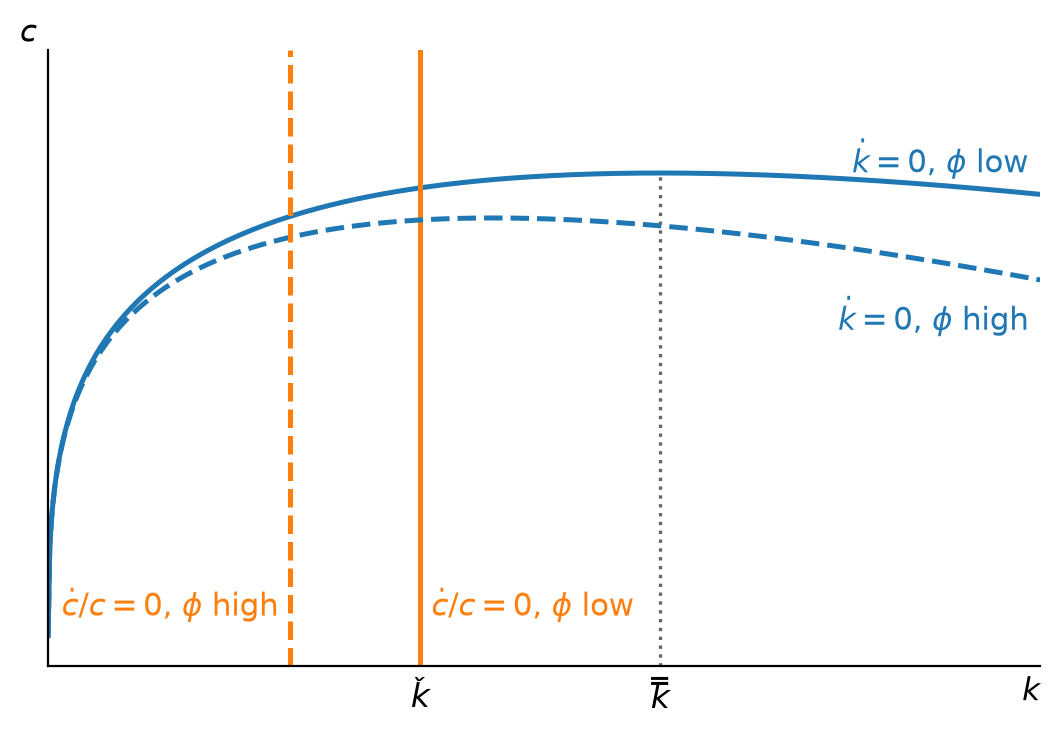

In [ ]:
e = Economy()
fast = replace(e, phi=0.06)
k = np.linspace(1e-4, 6, 600)
fig, ax = plt.subplots()
ramsey.draw_loci(ax, k, {r"$\phi$ low": (kdot_zero(e, k), steady_state(e)[0]),
                         r"$\phi$ high": (kdot_zero(fast, k), steady_state(fast)[0])},
                 golden=golden_rule(e))
style.save(fig, "RamseySSPlot")

## The transition

From $k_{0} = 0.5$, the saddle path's consumption leads to the steady state. Ten percent more consumption leads to the exhaustion of capital, and ten percent less to too much of it.

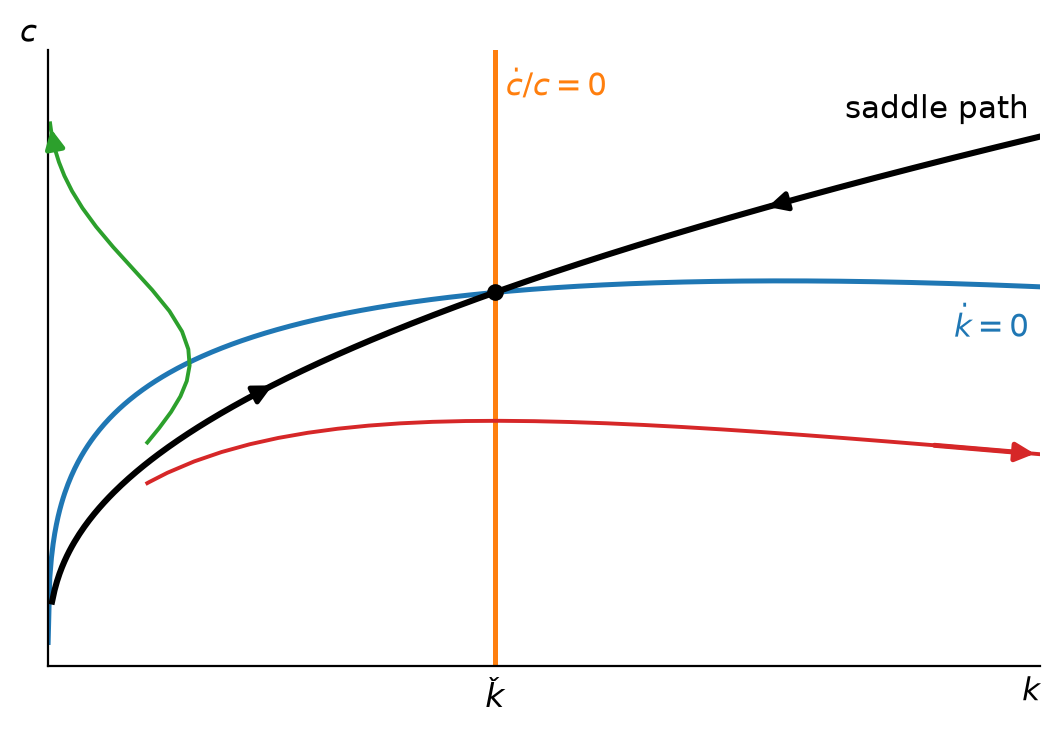

In [ ]:
k_ss, c_ss = steady_state(e)
k = np.linspace(1e-4, 5, 600)
saddle = saddle_path(e, 0.02, 5)
k_saddle = np.linspace(0.02, 5, 400)
k0 = 0.5
above, below = path(e, k0, 1.1 * saddle(k0), k_max=5), path(e, k0, 0.9 * saddle(k0), k_max=5)
fig, ax = plt.subplots()
ramsey.draw_saddle(ax, k, kdot_zero(e, k), (k_ss, c_ss), (k_saddle, saddle(k_saddle)), [above, below])
style.save(fig, "RamseySaddlePlot")

## A closed form

When relative risk aversion equals capital's share, $\rho = \alpha$, the saddle path is a ray, $c = \mu k$ with $\mu = (\vartheta + (1-\alpha)(\xi+\delta))/\alpha$ (Smith 2006). Time elimination finds the same path. With $\rho$ this low, $\nu$ is positive only if growth is slower, so the check uses $\phi = 0.01$.

In [ ]:
ray = replace(e, rho=e.alpha, phi=0.01)
mu = (ray.theta + (1 - ray.alpha) * (ray.xi + ray.delta)) / ray.alpha
k = np.linspace(0.1, 5, 50)
gap = np.max(np.abs(saddle_path(ray, 0.1, 5)(k) / (mu * k) - 1))
print(f"The ray's slope is {mu:.4f}; time elimination's path is within {gap:.0e} of it, in proportion.")

The ray's slope is 0.2767; time elimination's path is within 3e-13 of it, in proportion.


## Checks

The numbers above: the steady state, the golden rule, and where each path goes.

In [ ]:
k_ss, c_ss = steady_state(e)
assert round(k_ss, 3) == 2.251 and round(c_ss, 3) == 1.005 and round(golden_rule(e), 2) == 3.70
assert np.isclose(e.nu, 0.05)
# f'(k_ss) - f'(k_gold) = nu, so the steady state is below the golden rule exactly when nu > 0.
fprime = lambda e, k: e.alpha * k ** (e.alpha - 1)
assert np.isclose(fprime(e, k_ss) - fprime(e, golden_rule(e)), e.nu) and k_ss < golden_rule(e)
# Faster growth lowers the steady state and the kdot = 0 locus.
assert steady_state(fast)[0] < k_ss and np.all(kdot_zero(fast, k_saddle) < kdot_zero(e, k_saddle))
# The saddle path passes through the steady state, rises with k, and solves the equations: started on
# it, the economy comes within a thousandth of the steady state (before the smallest numerical error,
# which the equations magnify, takes it away again).
assert np.isclose(saddle(k_ss), c_ss) and np.all(np.diff(saddle(k_saddle)) > 0)
k_on, c_on = path(e, k0, saddle(k0), k_max=5)
assert np.min(np.hypot(k_on / k_ss - 1, c_on / c_ss - 1)) < 1e-3
# Above it, capital runs out; below it, capital passes the golden rule.
assert above[0, -1] < 0.02 and below[0, -1] >= 5 > golden_rule(e)
# The closed form: within a millionth.
assert gap < 1e-6